# **L3 Lab: Time Series and Sequences – Energy Consumption Forecasting**

<b>Information on group members:</b><br>
1) **Kuba Czech**, 156035 <br>
2) **Wojciech Nagórka**, 156045

Forecasting hourly electricity consumption of four customers (`TS0277`, `TS3423`, `TS3449`, `TS4011`) with LSTMs, dynamic calendar inputs and static features following Miebs et al. (2020), *Efficient Strategies of Static Features Incorporation into the Recurrent Neural Network*.

**Setup in one paragraph.** The 15-min readings are cleaned (DST duplicates/gaps) and averaged to **hourly** values. Every model reads the last
**168 h (one week)** and predicts the next **24 h at once** (horizons $h=1\dots24$). Each series is normalized by its **training mean**, and its
**last 365 days** are the test year; the last 60 days of the training part are used for early stopping. Static features use the last **28 days** of
history, so test forecasts start ≥ 28 days into the test year and no input, static-feature or target window crosses the train/test boundary.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import linregress
from statsmodels.tsa.seasonal import MSTL, seasonal_decompose

import ts_lib as T

warnings.filterwarnings("ignore")
torch.set_num_threads(8)
pd.set_option("display.precision", 4)
DATA_DIR = "../data/lab3"

# fixed categorical palette: colour follows the entity, never the rank
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#8a5cd1", "#6b6b6b"]
SCOL = dict(zip(T.SERIES, PALETTE))
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.6})

## **1. Data loading and cleaning**

In [2]:
rows = []
for n in T.SERIES:
    raw = pd.read_csv(f"{DATA_DIR}/{n}.csv.gz", header=None, names=["t", "y"], parse_dates=["t"])
    gaps = raw["t"].diff().value_counts()
    rows.append({"series": n, "start": raw.t.min(), "end": raw.t.max(), "rows": len(raw),
                 "duplicate stamps (DST autumn)": int(raw.t.duplicated().sum()),
                 "1h gaps (DST spring)": int(gaps.get(pd.Timedelta("75min"), 0)),
                 "zeros": int((raw.y == 0).sum()), "mean": raw.y.mean(), "std": raw.y.std(), "max": raw.y.max()})
display(pd.DataFrame(rows).set_index("series"))

hourly = {n: T.load_hourly(DATA_DIR, n) for n in T.SERIES}
print({n: len(h) for n, h in hourly.items()}, "hourly steps")

,start,end,rows,duplicate stamps (DST autumn),1h gaps (DST spring),zeros,mean,std,max
series,,,,,,,,,
TS0277,2001-01-01,2005-12-31 23:45:00,175296,20,5,26,94.1708,71.2050,241.10
TS3423,2001-01-01,2005-12-31 23:45:00,175296,20,5,4,48.5390,24.1237,101.00
TS3449,2002-01-09,2005-12-31 23:45:00,139488,16,4,47,23.9190,18.7638,102.05
TS4011,2001-01-01,2002-12-31 23:45:00,70080,8,2,1,12.9126,12.5985,46.25


{'TS0277': 43824, 'TS3423': 43824, 'TS3449': 34872, 'TS4011': 17520} hourly steps


Timestamps are local time: every autumn one hour appears twice (4 stamps) and every spring one hour is missing. Duplicated stamps are
averaged, the missing hour is linearly interpolated, and the regular 15-min grid is averaged to hourly values (`ts_lib.load_hourly`).
`TS4011` covers only two years (2001–2002), `TS3449` starts in January 2002.

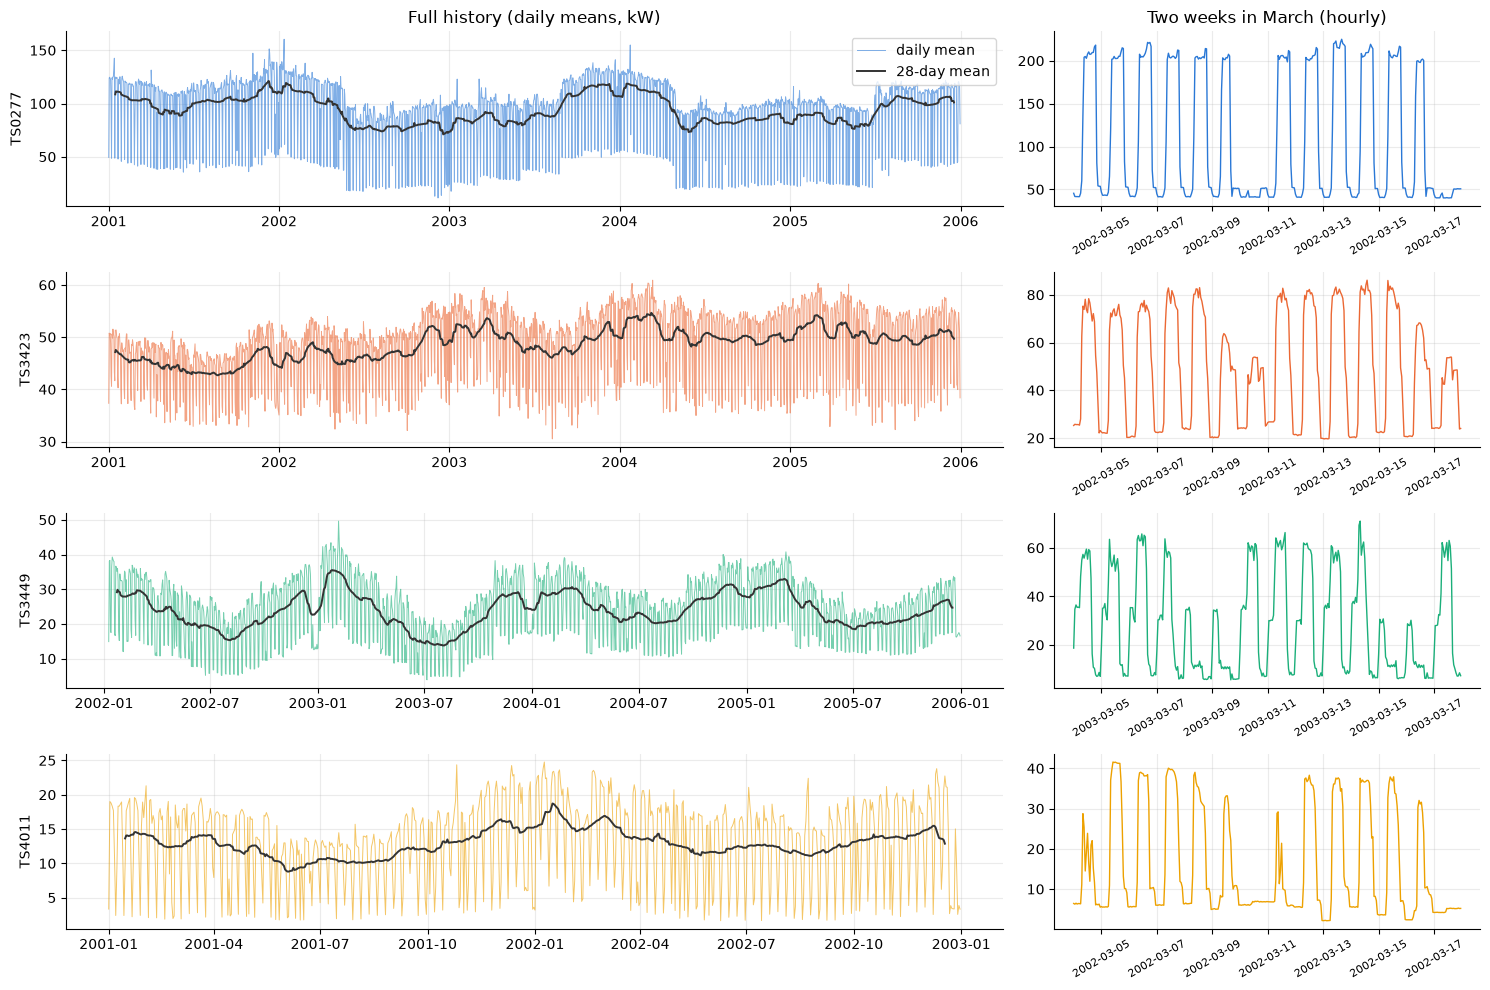

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [2.2, 1]})
for i, n in enumerate(T.SERIES):
    h = hourly[n]; d = h.resample("D").mean()
    axes[i, 0].plot(d.index, d, color=SCOL[n], lw=0.7, alpha=0.6, label="daily mean")
    axes[i, 0].plot(d.rolling(28, center=True).mean(), color="#333333", lw=1.4, label="28-day mean")
    axes[i, 0].set_ylabel(n)
    wk = h[f"{h.index[0].year + 1}-03-04":f"{h.index[0].year + 1}-03-17"]
    axes[i, 1].plot(wk.index, wk, color=SCOL[n], lw=1.0)
    axes[i, 1].tick_params(axis="x", labelrotation=30, labelsize=8)
axes[0, 0].legend(loc="upper right"); axes[0, 0].set_title("Full history (daily means, kW)")
axes[0, 1].set_title("Two weeks in March (hourly)")
plt.tight_layout(); plt.show()

## **2. Decomposition into seasonal, trend and residual components**

Four time scales are examined:

* **daily and weekly** – on hourly data with **MSTL** (multiple STL), which extracts a 24 h and a 168 h seasonal component jointly, plus trend and residual;
* **monthly** – on daily means with a 30-day additive decomposition (does a within-month cycle exist?);
* **yearly** – on daily means with a 365-day additive decomposition (the trend is then a 1-year moving average).

The strength of a component is measured as in Hyndman & Athanasopoulos: $F_S = \max(0, 1 - \mathrm{Var}(R)/\mathrm{Var}(S+R))$, analogous for trend.

In [4]:
def strength(c, r):
    return max(0.0, 1 - np.var(r) / np.var(c + r))

mstl, yearly, monthly, rows = {}, {}, {}, []
for n in T.SERIES:
    h = hourly[n]; d = h.resample("D").mean()
    m = MSTL(h, periods=(24, 168)).fit(); mstl[n] = m
    y = seasonal_decompose(d, period=365, extrapolate_trend="freq"); yearly[n] = y
    mo = seasonal_decompose(d, period=30, extrapolate_trend="freq"); monthly[n] = mo
    s24, s168 = m.seasonal["seasonal_24"], m.seasonal["seasonal_168"]
    v = h.var()
    rows.append({"series": n,
                 "daily  var share": s24.var() / v, "daily  F_S": strength(s24, m.resid),
                 "weekly var share": s168.var() / v, "weekly F_S": strength(s168, m.resid),
                 "trend var share": m.trend.var() / v, "resid var share": m.resid.var() / v,
                 "monthly(30d) F_S": strength(mo.seasonal, mo.resid),
                 "yearly F_S": strength(y.seasonal, y.resid), "yearly F_T": strength(y.trend, y.resid)})
decomp_df = pd.DataFrame(rows).set_index("series")
display(decomp_df.round(3))

,daily var share,daily F_S,weekly var share,weekly F_S,trend var share,resid var share,monthly(30d) F_S,yearly F_S,yearly F_T
series,,,,,,,,,
TS0277,0.640,0.932,0.264,0.850,0.038,0.047,0.004,0.192,0.112
TS3423,0.850,0.977,0.107,0.844,0.018,0.020,0.004,0.212,0.154
TS3449,0.546,0.918,0.303,0.862,0.082,0.049,0.005,0.450,0.036
TS4011,0.526,0.869,0.330,0.808,0.036,0.081,0.017,0.773,0.052


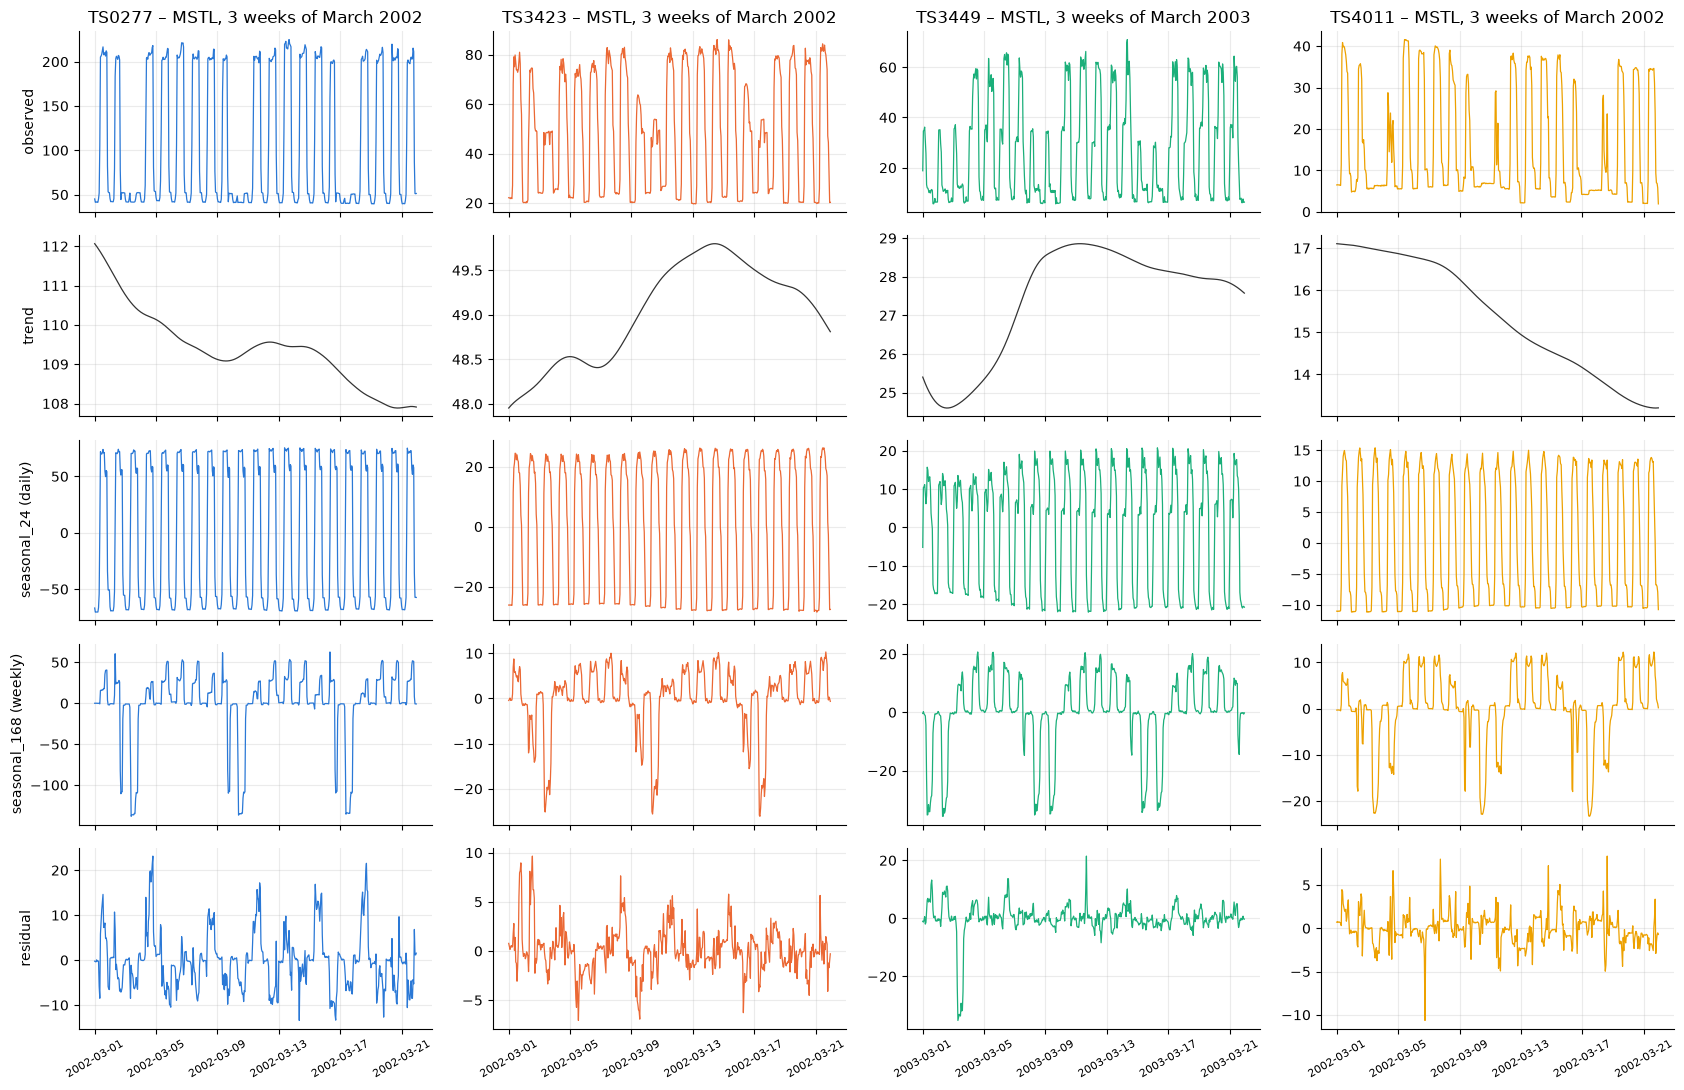

In [5]:
fig, axes = plt.subplots(5, 4, figsize=(17, 11), sharex="col")
names = ["observed", "trend", "seasonal_24 (daily)", "seasonal_168 (weekly)", "residual"]
for j, n in enumerate(T.SERIES):
    m = mstl[n]; yr = hourly[n].index[0].year + 1
    sl = slice(f"{yr}-03-01", f"{yr}-03-21")
    comps = [m.observed, m.trend, m.seasonal["seasonal_24"], m.seasonal["seasonal_168"], m.resid]
    for i, c in enumerate(comps):
        axes[i, j].plot(c[sl], color=SCOL[n] if i != 1 else "#333333", lw=0.9)
        if j == 0: axes[i, j].set_ylabel(names[i])
    axes[0, j].set_title(f"{n} – MSTL, 3 weeks of March {yr}")
    axes[-1, j].tick_params(axis="x", labelrotation=30, labelsize=8)
plt.tight_layout(); plt.show()

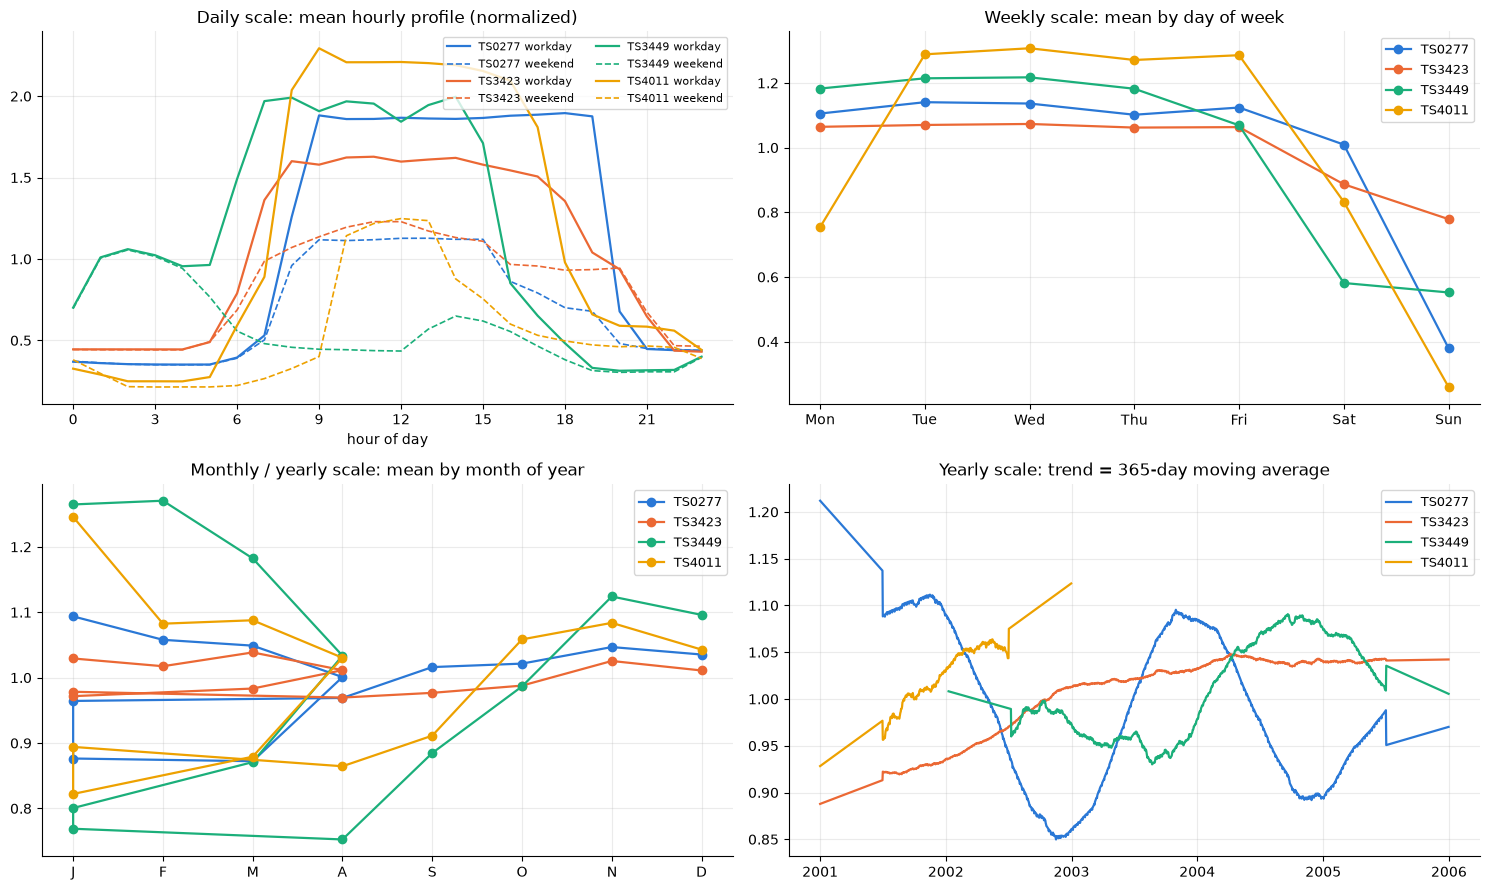

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
dows = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
months = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
for n in T.SERIES:
    h = hourly[n] / hourly[n].mean()
    we = h.index.dayofweek >= 5
    a = axes[0, 0]
    a.plot(h[~we].groupby(h.index[~we].hour).mean(), color=SCOL[n], label=f"{n} workday")
    a.plot(h[we].groupby(h.index[we].hour).mean(), color=SCOL[n], ls="--", lw=1.2, label=f"{n} weekend")
    axes[0, 1].plot(dows, h.groupby(h.index.dayofweek).mean().values, "o-", color=SCOL[n], label=n)
    d = h.resample("D").mean()
    axes[1, 0].plot(months, d.groupby(d.index.month).mean().values, "o-", color=SCOL[n], label=n)
    tr = yearly[n].trend / hourly[n].mean()
    axes[1, 1].plot(tr.index, tr, color=SCOL[n], label=n)
axes[0, 0].set(title="Daily scale: mean hourly profile (normalized)", xlabel="hour of day", xticks=range(0, 24, 3))
axes[0, 1].set(title="Weekly scale: mean by day of week")
axes[1, 0].set(title="Monthly / yearly scale: mean by month of year")
axes[1, 1].set(title="Yearly scale: trend = 365-day moving average")
axes[0, 0].legend(ncol=2, fontsize=8)
for a in axes.flat[1:]: a.legend(fontsize=9)
plt.tight_layout(); plt.show()

In [7]:
# numbers quoted in the description below
desc = []
for n in T.SERIES:
    h = hourly[n] / hourly[n].mean(); d = h.resample("D").mean()
    prof = h.groupby(h.index.hour).mean(); dow = h.groupby(h.index.dayofweek).mean(); mon = d.groupby(d.index.month).mean()
    tr = yearly[n].trend.resample("YE").mean()
    desc.append({"series": n, "night 0-5h": prof[0:6].mean(), "day 8-16h": prof[8:17].mean(), "peak hour": prof.idxmax(),
                 "Sat": dow[5], "Sun": dow[6], "Mon-Fri": dow[:5].mean(),
                 "winter (DJF)": mon[[12, 1, 2]].mean(), "summer (JJA)": mon[[6, 7, 8]].mean(),
                 "trend first→last year %": 100 * (tr.iloc[-1] / tr.iloc[0] - 1),
                 "resid std / mean (hourly)": mstl[n].resid.std() / hourly[n].mean()})
display(pd.DataFrame(desc).set_index("series").round(2))

,night 0-5h,day 8-16h,peak hour,Sat,Sun,Mon-Fri,winter (DJF),summer (JJA),trend first→last year %,resid std / mean (hourly)
series,,,,,,,,,,
TS0277,0.36,1.59,9,1.01,0.38,1.12,1.06,0.94,-16.32,0.16
TS3423,0.45,1.47,11,0.89,0.78,1.07,1.02,0.97,14.00,0.07
TS3449,0.94,1.43,14,0.58,0.55,1.17,1.21,0.77,4.44,0.17
TS4011,0.27,1.80,12,0.83,0.26,1.18,1.12,0.86,10.15,0.27


### Description of the components

**Daily scale (24 h).** The diurnal cycle is the dominant component of every series (55–85 % of the hourly variance, $F_S \approx 0.9$–$0.98$).
`TS0277`, `TS4011` and `TS3423` are typical business/industrial profiles: low night load (≈0.25–0.45 × mean), a steep ramp-up 6–8 h and a plateau during working hours with the peak around 9–12 h. `TS3449` is different – its night consumption is almost as high as the daytime one and its minimum is in the evening (≈20 h); together with its strong winter peak this looks like night-tariff (storage) electric heating.

**Weekly scale (168 h).** The weekly component adds another 11–33 % of variance ($F_S \approx 0.81$–$0.86$) and mainly encodes the weekend.
`TS4011` and `TS3449` behave like 5-day businesses (Sat/Sun ≈ 0.3–0.6 × weekdays), `TS0277` works six days (Saturday is close to normal, Sunday ≈ 0.4), while `TS3423` keeps ≈ 80 % of its load on weekends (continuous operation). `TS4011` also has a lower Monday. The weekly component is not just a repetition of the daily one – weekend days also have a *different shape* (dashed curves).

**Monthly scale.** A 30-day decomposition of daily means finds no within-month cycle ($F_S \approx 0$): consumption does not depend on the day of the month. What changes from month to month is the slowly varying level, which belongs to the yearly season/trend. Short-lived dips are caused by holidays (Christmas, Easter, May 1st/3rd, long summer weekends) – these appear in the residuals of every decomposition.

**Yearly scale.** Three customers are winter-peaking (heating/lighting): `TS3449` (winter ≈ 1.25 vs summer ≈ 0.8 × mean), `TS4011` and `TS0277` (summer dip, especially May–June for `TS0277`). `TS3423` has almost no yearly season but the only clear **trend**: +14 % between 2001 and 2005.
`TS0277` shows a level drop after 2001 and is roughly flat afterwards; `TS3449` and `TS4011` show mild increases.
*Caveat for `TS4011`:* the series covers exactly two years (730 days), so the centred 365-day moving average is defined only for the middle
366 days and the rest of the trend is extrapolated; the seasonal estimate rests on essentially one cycle per calendar day. Its yearly
$F_S = 0.77$ and the +10 % trend should therefore be read as rough estimates, not as evidence of a stronger yearly season than in the other series.

**Residuals.** After removing trend and both seasonalities, 2–8 % of the hourly variance remains – mostly holidays, irregular shutdowns and
hour-to-hour noise. `TS4011` (smallest customer, 1 year of training data) is the noisiest, `TS3423` the most regular.

**Consequences for modelling.** (i) An input window of one week covers both dominant cycles; (ii) the weekly component means a model must
know *which day* it is forecasting – calendar inputs should help; (iii) level changes (trend, yearly season) motivate normalization and static
features describing the recent level, e.g. the last-28-days mean and percentiles.

## **3. Normalization and chronological split**

* Test = last 365 days (2005 for `TS0277`, `TS3423`, `TS3449`; 2002 for `TS4011`).
* Training = everything before; its last 60 days are the validation period for early stopping.
* Normalization: divide by the **mean of the training period only**.
* A sample is a forecast origin $t_0$; it uses $y[t_0-168:t_0]$ as dynamic input, $y[t_0-672:t_0]$ for static features and predicts $y[t_0:t_0+24]$.
  Training origins satisfy $t_0+24 \le$ validation start, validation origins $t_0+24 \le$ test start, and test origins $t_0-672 \ge$ test start –
  so **neither the input sequence, the static-feature history nor the forecast window crosses the train/test boundary**.

In [8]:
data = {n: T.prepare(DATA_DIR, n) for n in T.SERIES}
rows = []
for n, d in data.items():
    idx = d.hourly.index
    tr, va, te = d.t0["train"], d.t0["val"], d.t0["test"]
    # leakage checks
    assert tr.max() + T.H <= d.val_start and va.max() + T.H <= d.test_start
    assert te.min() - T.LOOKBACK >= d.test_start and te.max() + T.H <= len(d.y)
    assert np.isclose(d.y[:d.test_start].mean(), 1.0)
    rows.append({"series": n, "train mean (kW)": d.mean, "train": f"{idx[0]:%Y-%m-%d} – {idx[d.val_start-1]:%Y-%m-%d}",
                 "val": f"{idx[d.val_start]:%Y-%m-%d} – {idx[d.test_start-1]:%Y-%m-%d}",
                 "test": f"{idx[d.test_start]:%Y-%m-%d} – {idx[-1]:%Y-%m-%d}",
                 "train origins": len(tr), "val origins": len(va), "test origins": len(te),
                 "test-year mean (normalized)": d.y[d.test_start:].mean()})
display(pd.DataFrame(rows).set_index("series"))
print("all window/leakage assertions passed")

,train mean (kW),train,val,test,train origins,val origins,test origins,test-year mean (normalized)
series,,,,,,,,
TS0277,94.4539,2001-01-01 – 2004-11-01,2004-11-02 – 2004-12-31,2005-01-01 – 2005-12-31,32929,1417,8065,0.9850
TS3423,48.0232,2001-01-01 – 2004-11-01,2004-11-02 – 2004-12-31,2005-01-01 – 2005-12-31,32929,1417,8065,1.0538
TS3449,23.8470,2002-01-09 – 2004-11-01,2004-11-02 – 2004-12-31,2005-01-01 – 2005-12-31,23977,1417,8065,1.0120
TS4011,12.3497,2001-01-01 – 2001-11-01,2001-11-02 – 2001-12-31,2002-01-01 – 2002-12-31,6625,1417,8065,1.0912


all window/leakage assertions passed


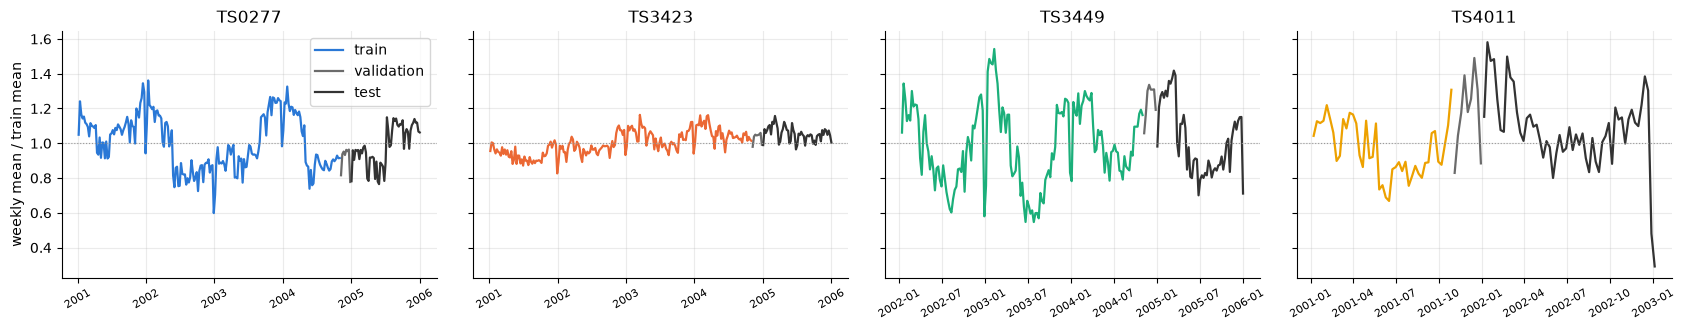

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
for a, (n, d) in zip(axes, data.items()):
    w = pd.Series(d.y, d.hourly.index).resample("W").mean()
    a.plot(w[:d.hourly.index[d.val_start]], color=SCOL[n], label="train")
    a.plot(w[d.hourly.index[d.val_start]:d.hourly.index[d.test_start]], color="#6b6b6b", label="validation")
    a.plot(w[d.hourly.index[d.test_start]:], color="#333333", label="test")
    a.axhline(1, color="#999999", lw=0.8, ls=":"); a.set_title(n); a.tick_params(axis="x", labelrotation=30, labelsize=8)
axes[0].set_ylabel("weekly mean / train mean"); axes[0].legend()
plt.tight_layout(); plt.show()

## **4. Per-series LSTM and forecast quality vs. horizon**

**Architecture** (`ts_lib.Forecaster`, `static_mode="none"`): a direct multi-horizon (MIMO) model

$$\hat y_{t_0..t_0+23} \;=\; \underbrace{W_{\text{skip}}\, y_{t_0-168..t_0-1}}_{\text{linear highway}} \;+\; \underbrace{\text{Dense}(24)\big(\text{ReLU}(\text{Dense}(128)(h_{t_0-1}))\big)}_{\text{LSTM branch}}, \qquad h_{t_0-1} = \text{LSTM}(64)(x_{t_0-168..t_0-1}).$$

Predicting all 24 steps at once avoids error accumulation of recursive one-step forecasting and lets us read the error of every horizon from one model.
The **linear highway** (as in LSTNet) maps the raw input week directly to the 24 outputs and is initialized to the weekly seasonal-naive forecast
$\hat y_{t_0+k} = y_{t_0+k-168}$; the LSTM therefore learns a *correction* to a strong baseline (residual learning). A first version without it
underfitted badly on the CPU budget available (preliminary runs, not shown: it was worse than the naive forecast) – the highway made the optimization much easier.
Training: MSE loss, Adam (lr = 2·10⁻³, batch 256), ReduceLROnPlateau, early stopping on the validation period (patience 4, ≤ 15 epochs),
training origins every 3 h (every hour for the short `TS4011`; adjacent hourly windows are nearly identical). One model per series. A 1-layer LSTM with 64 units was chosen after a CPU timing
benchmark (not shown): a 2-layer version was ~2.5× slower without a visible gain in short tests.

**Baselines.** Seasonal-naive forecasts that copy the value from one day ago ($\hat y_{t}=y_{t-24}$) or one week ago ($\hat y_t = y_{t-168}$).

**Metrics** are computed in normalized units (consumption / training mean), so **MAE and RMSE are relative to the customer's mean load** and comparable
across customers (e.g. RMSE = 0.10 ≙ 10 % of the mean consumption). They are evaluated on every hourly origin of the test year (≈ 8 000 forecasts per series).

In [10]:
def run_per_series(cal):
    out = {}
    for n in T.SERIES:
        m, hist, preds = T.run_experiment(f"per_{n}_{'cal' if cal else 'y'}", [data[n]], use_cal=cal,
                                          stride=1 if n == "TS4011" else 3)
        out[n] = (m[n], hist, preds[n])
    return out

per_y = run_per_series(cal=False)
naive24 = {n: T.naive_metrics(data[n], 24) for n in T.SERIES}
naive168 = {n: T.naive_metrics(data[n], 168) for n in T.SERIES}

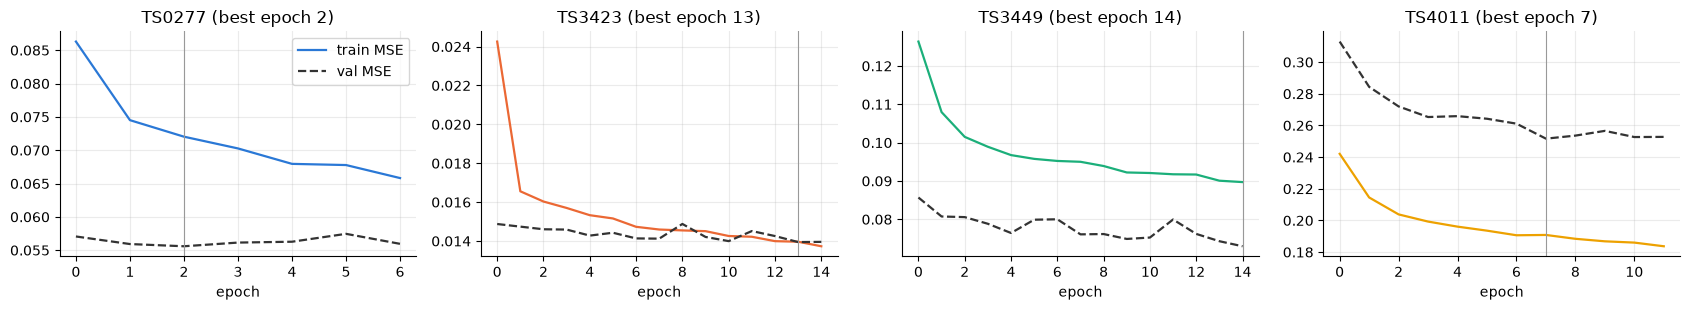

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for a, n in zip(axes, T.SERIES):
    hist = np.array(per_y[n][1])
    a.plot(hist[:, 0], color=SCOL[n], label="train MSE"); a.plot(hist[:, 1], color="#333333", ls="--", label="val MSE")
    a.axvline(hist[:, 1].argmin(), color="#999999", lw=0.8); a.set_title(f"{n} (best epoch {hist[:, 1].argmin()})"); a.set_xlabel("epoch")
axes[0].legend(); plt.tight_layout(); plt.show()

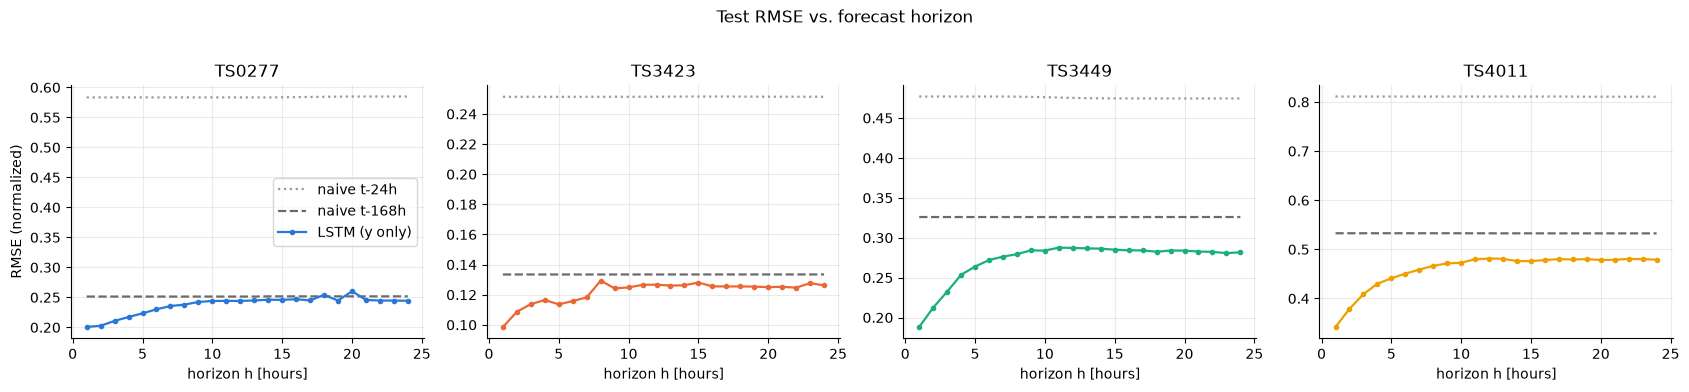

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharex=True)
for a, n in zip(axes, T.SERIES):
    a.plot(naive24[n].horizon, naive24[n].RMSE, color="#9a9a9a", ls=":", label="naive t-24h")
    a.plot(naive168[n].horizon, naive168[n].RMSE, color="#6b6b6b", ls="--", label="naive t-168h")
    a.plot(per_y[n][0].horizon, per_y[n][0].RMSE, color=SCOL[n], marker="o", ms=3, label="LSTM (y only)")
    a.set_title(n); a.set_xlabel("horizon h [hours]")
axes[0].set_ylabel("RMSE (normalized)"); axes[0].legend()
plt.suptitle("Test RMSE vs. forecast horizon", y=1.02); plt.tight_layout(); plt.show()

In [13]:
def horizon_summary(res, label):
    rows = []
    for n in T.SERIES:
        m = res[n] if isinstance(res[n], pd.DataFrame) else res[n][0]
        r = m.set_index("horizon")
        slope = linregress(r.index, r.RMSE)
        plateau = r.RMSE.iloc[-6:].mean()
        rows.append({"model": label, "series": n,
                     "RMSE h=1": r.RMSE[1], "h=3": r.RMSE[3], "h=6": r.RMSE[6], "h=12": r.RMSE[12], "h=24": r.RMSE[24],
                     "mean RMSE": r.RMSE.mean(), "mean MAE": r.MAE.mean(),
                     "RMSE h24/h1": r.RMSE[24] / r.RMSE[1], "RMSE slope/h": slope.slope,
                     "h reaching 90% of plateau": int(r.index[np.argmax(r.RMSE.values >= 0.9 * plateau)]),
                     "skill vs naive-168 (mean)": 1 - r.RMSE.mean() / naive168[n].RMSE.mean()})
    return pd.DataFrame(rows).set_index(["model", "series"])

hz_y = horizon_summary(per_y, "LSTM y-only")
display(pd.concat([horizon_summary(naive24, "naive t-24h"), horizon_summary(naive168, "naive t-168h"), hz_y]).round(4))

RMSE h=1     h=3     h=6    h=12    h=24  mean RMSE  \
model        series                                                        
naive t-24h  TS0277    0.5833  0.5833  0.5833  0.5833  0.5848     0.5838   
             TS3423    0.2514  0.2514  0.2514  0.2515  0.2514     0.2515   
             TS3449    0.4770  0.4770  0.4770  0.4753  0.4745     0.4756   
             TS4011    0.8111  0.8111  0.8111  0.8111  0.8107     0.8110   
naive t-168h TS0277    0.2514  0.2513  0.2513  0.2514  0.2517     0.2515   
             TS3423    0.1334  0.1334  0.1334  0.1334  0.1335     0.1334   
             TS3449    0.3259  0.3259  0.3259  0.3259  0.3259     0.3259   
             TS4011    0.5328  0.5328  0.5328  0.5327  0.5325     0.5326   
LSTM y-only  TS0277    0.2006  0.2108  0.2301  0.2440  0.2444     0.2375   
             TS3423    0.0986  0.1138  0.1158  0.1267  0.1262     0.1220   
             TS3449    0.1882  0.2324  0.2720  0.2871  0.2818     0.2719   
             TS4011    0.3420  0.4089  0.4505  0.4813  0.4789     0.4595   

                     mean MAE  RMSE h24/h1  RMSE slope/h  \
model        series                                        
naive t-24h  TS0277    0.2595       1.0025        0.0001   
             TS3423    0.1358       1.0003        0.0000   
             TS3449    0.2343       0.9949       -0.0001   
             TS4011    0.4518       0.9995       -0.0000   
naive t-168h TS0277    0.0891       1.0014        0.0000   
             TS3423    0.0701       1.0002        0.0000   
             TS3449    0.1592       1.0000        0.0000   
             TS4011    0.2601       0.9994       -0.0000   
LSTM y-only  TS0277    0.1195       1.2179        0.0018   
             TS3423    0.0746       1.2801        0.0008   
             TS3449    0.1646       1.4976        0.0024   
             TS4011    0.2727       1.4004        0.0038   

                     h reaching 90% of plateau  skill vs naive-168 (mean)  
model        series                                                        
naive t-24h  TS0277                          1                    -1.3210  
             TS3423                          1                    -0.8844  
             TS3449                          1                    -0.4591  
             TS4011                          1                    -0.5226  
naive t-168h TS0277                          1                     0.0000  
             TS3423                          1                     0.0000  
             TS3449                          1                     0.0000  
             TS4011                          1                     0.0000  
LSTM y-only  TS0277                          5                     0.0558  
             TS3423                          3                     0.0857  
             TS3449                          5                     0.1659  
             TS4011                          5                     0.1372

### How does forecast quality change with the horizon?

* **Error grows quickly over the first hours and then saturates.** For every customer the RMSE increases steeply from $h=1$ to about $h=5$–$7$
  (the "h reaching 90 % of plateau" column), and is practically flat from $h \approx 10$ to $h=24$. Over the whole day the RMSE grows by a factor of
  only **1.2–1.5** ($h_{24}/h_1$), i.e. roughly **+0.001 to +0.004 normalized units per hour** of lead time (column `RMSE slope/h`, slope of a line fitted to RMSE over $h$), but most of this
  growth happens in the first quarter of the horizon.
* **Why?:** for the first hours, the last observed values are very informative (consumption is autocorrelated – the model behaves like a smart
  persistence forecast). Beyond a few hours this information is gone and the model falls back to what it knows about the *seasonal pattern*
  (same hour last week, typical daily shape). The seasonal pattern is equally informative for $h = 8$ and $h = 24$, hence the plateau.
  Unlike a recursive model, the direct 24-output model does not accumulate its own errors.
* **Customer predictability differs much more than horizons do.** `TS3423` (continuous operation, weak weekend effect) has the lowest error
  (≈ 0.10–0.13 of its mean load), `TS0277` ≈ 0.20–0.25, `TS3449` ≈ 0.19–0.29, and `TS4011` (smallest customer, only one training year) ≈ 0.34–0.48.
* **Against the baselines.** The LSTM beats the weekly seasonal-naive forecast for all customers (skill **6–17 %** on average over horizons, more at short horizons) and
  is far better than the daily-naive one (copying yesterday is bad because of weekends). At $h \ge 10$ the LSTM error approaches the naive level
  – the remaining improvement comes from smoothing out noise rather than from new information.

## **5. Dynamic calendar features**

Each input time step gets 7 extra channels: $\sin/\cos(2\pi\,\text{hour}/24)$, $\sin/\cos(2\pi\,\text{weekday}/7)$, $\sin/\cos(2\pi\,\text{day of year}/365.25)$ and an
is-weekend flag. Sin/cos encoding keeps 23 h next to 0 h and Sunday next to Monday with only 2 numbers per cycle.
Note that the calendar of the *forecast* window is implicitly known through the calendar of the last input step (the forecast starts one hour later).
Everything else (architecture, training, seed) is identical to section 4.

In [14]:
per_cal = run_per_series(cal=True)
hz_cal = horizon_summary(per_cal, "LSTM y + calendar")
cmp = pd.concat([hz_y, hz_cal]).round(3)
display(cmp)
delta = (hz_cal.droplevel(0)["mean RMSE"] / hz_y.droplevel(0)["mean RMSE"] - 1) * 100
print("relative change of mean RMSE with calendar inputs [%]:"); print(delta.round(1).to_string())

RMSE h=1    h=3    h=6   h=12   h=24  mean RMSE  \
model             series                                                    
LSTM y-only       TS0277     0.201  0.211  0.230  0.244  0.244      0.237   
                  TS3423     0.099  0.114  0.116  0.127  0.126      0.122   
                  TS3449     0.188  0.232  0.272  0.287  0.282      0.272   
                  TS4011     0.342  0.409  0.450  0.481  0.479      0.460   
LSTM y + calendar TS0277     0.150  0.165  0.184  0.209  0.212      0.200   
                  TS3423     0.082  0.090  0.099  0.109  0.112      0.105   
                  TS3449     0.199  0.245  0.259  0.268  0.274      0.262   
                  TS4011     0.363  0.400  0.441  0.478  0.464      0.456   

                          mean MAE  RMSE h24/h1  RMSE slope/h  \
model             series                                        
LSTM y-only       TS0277     0.119        1.218         0.002   
                  TS3423     0.075        1.280         0.001   
                  TS3449     0.165        1.498         0.002   
                  TS4011     0.273        1.400         0.004   
LSTM y + calendar TS0277     0.108        1.410         0.002   
                  TS3423     0.065        1.358         0.001   
                  TS3449     0.180        1.374         0.002   
                  TS4011     0.285        1.278         0.003   

                          h reaching 90% of plateau  skill vs naive-168 (mean)  
model             series                                                        
LSTM y-only       TS0277                          5                      0.056  
                  TS3423                          3                      0.086  
                  TS3449                          5                      0.166  
                  TS4011                          5                      0.137  
LSTM y + calendar TS0277                          7                      0.205  
                  TS3423                          7                      0.213  
                  TS3449                          4                      0.195  
                  TS4011                          5                      0.144

relative change of mean RMSE with calendar inputs [%]:
series
TS0277   -15.8
TS3423   -14.0
TS3449    -3.5
TS4011    -0.8


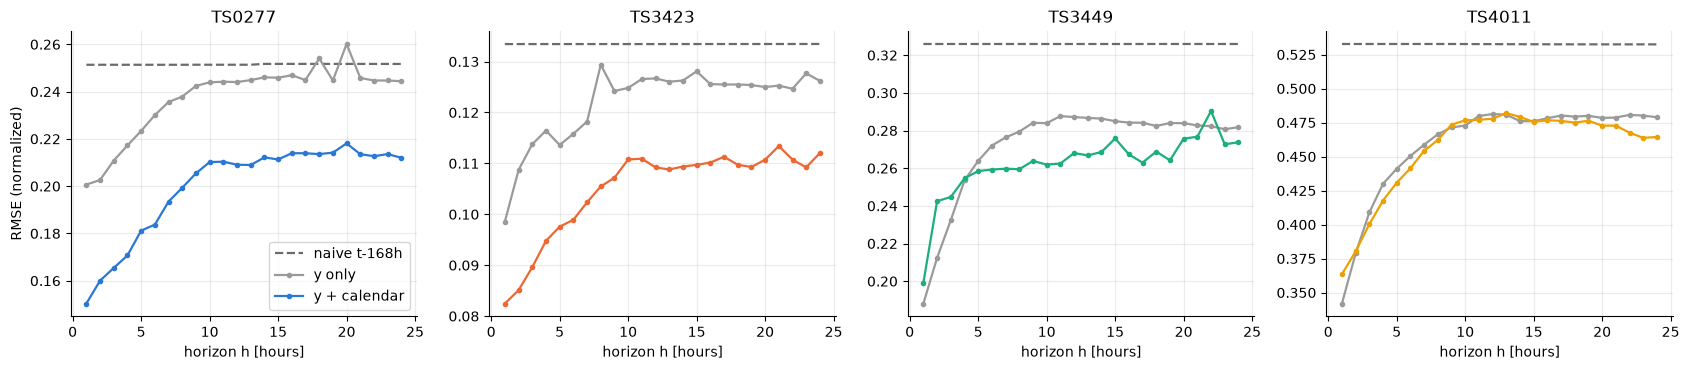

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharex=True)
for a, n in zip(axes, T.SERIES):
    a.plot(naive168[n].horizon, naive168[n].RMSE, color="#6b6b6b", ls="--", label="naive t-168h")
    a.plot(per_y[n][0].horizon, per_y[n][0].RMSE, color="#9a9a9a", marker="o", ms=3, label="y only")
    a.plot(per_cal[n][0].horizon, per_cal[n][0].RMSE, color=SCOL[n], marker="o", ms=3, label="y + calendar")
    a.set_title(n); a.set_xlabel("horizon h [hours]")
axes[0].set_ylabel("RMSE (normalized)"); axes[0].legend()
plt.tight_layout(); plt.show()

### Do calendar features improve the forecast?

**Yes for the two customers with a regular weekly schedule, marginally or not at all for the other two:**

* `TS0277` (6-day business, Sunday ≈ 0.4) – mean RMSE **0.237 → 0.200 (−16 %)**, improvement at every horizon, largest at $h=1$ (0.201 → 0.150).
* `TS3423` (continuous operation) – **0.122 → 0.105 (−14 %)**, again at every horizon.
* `TS3449` – RMSE −3.5 % but MAE +9 %: the model got better on large errors (winter heating days) but slightly worse on typical hours.
* `TS4011` – practically unchanged (RMSE −1 %, MAE +4 %). With only one year of training data the model cannot learn a reliable mapping from day of year
  to consumption, and the extra 7 channels mostly add parameters to fit.

Note that each per-series model was trained with a single seed. The seed-to-seed spread measured for the generic models in section 7
(about 1–7 % of RMSE, largest for `TS3449`) means that the −3.5 % and −1 % changes for `TS3449` and `TS4011` are within noise, while
the −14 to −16 % improvements for `TS0277` and `TS3423` are clearly larger.

Without calendar inputs the model must infer the weekday from the shape of the last week (possible, but ambiguous around holidays and for
the 6-day profile of `TS0277`). An explicit hour/weekday encoding resolves this ambiguity and makes the weekend transitions (Friday → Saturday,
Sunday → Monday) predictable. The benefit is largest where the weekly component is strong and regular *and* there are several years of training
data. Calendar inputs are kept for all generic models below.

## **6. Static features**

Static features describe the *situation at the forecast origin* $t_0$ and are computed **only from the 28 days before $t_0$** plus the calendar of $t_0$
(`ts_lib.static_features`) – 48 values in 6 groups:

| group | features | why |
|---|---|---|
| calendar of the first forecast step (7) | sin/cos hour, weekday, day-of-year of $t_0$, weekend flag | what part of the daily/weekly/yearly cycle the forecast covers |
| aggregates (6) | mean over 28 d / 7 d / 1 d, std over 28 d and 1 d, std of the 28 daily means | recent level (= "monthly volume" in normalized units) and volatility |
| percentiles (8) | 0, 10, 20, 40, 60, 80, 90, 100th percentile of the last 28 days | distribution of the load: base load, typical day level, peak |
| trend (2) | slope of a line fitted to the 28 daily means; mean of last 7 d / mean of previous 21 d | level shifts, holidays, seasonal ramp |
| typical daily profile (24) | mean value of the last 28 days at hour $t_0+k$, $k=0..23$ | a ready "climatological" forecast of the next 24 h, aligned to $t_0$ |
| weekend/weekday ratio (1) | mean weekend day / mean weekday over 28 d | customer type (5-day / 6-day / continuous) |

The features are standardized with the mean/std of the pooled training origins. Because the values are normalized by each customer's training mean,
they describe the *shape* of the customer's consumption, which is exactly what distinguishes the four customers. The leakage check below
overwrites all data from $t_0$ on with garbage and verifies that the static features at $t_0$ do not change.

In [16]:
d = data["TS3449"]; idx = d.hourly.index
t0s = d.t0["test"][[0, 1000, 5000]]
f_ref, names = T.static_features(d.y, idx, t0s)
for t0, ref in zip(t0s, f_ref):
    y_bad = d.y.copy(); y_bad[t0:] = 1e6
    f_bad, _ = T.static_features(y_bad, idx, np.array([t0]))
    assert np.allclose(ref, f_bad[0])
print("static features use only past data: OK")

ex = pd.DataFrame({n: T.static_features(data[n].y, data[n].hourly.index, data[n].t0["test"][[2000]])[0][0] for n in T.SERIES},
                  index=names)
print("static features at the 2000th test origin of each customer:",
      {n: str(data[n].hourly.index[data[n].t0["test"][2000]]) for n in T.SERIES})
display(ex.loc[[c for c in names if not c.startswith("profile_h")]].round(3).T)

static features use only past data: OK
static features at the 2000th test origin of each customer: {'TS0277': '2005-04-22 08:00:00', 'TS3423': '2005-04-22 08:00:00', 'TS3449': '2005-04-22 08:00:00', 'TS4011': '2002-04-22 08:00:00'}


,t0_hour_sin,t0_hour_cos,t0_dow_sin,t0_dow_cos,t0_doy_sin,t0_doy_cos,t0_weekend,mean_28d,std_28d,mean_7d,...,p10_28d,p20_28d,p40_28d,p60_28d,p80_28d,p90_28d,p100_28d,trend_slope_28d,ratio_7d_vs_prev21d,weekend_weekday_ratio
TS0277,0.866,-0.5,-0.434,-0.901,0.937,-0.348,0.0,0.858,0.714,0.922,...,0.228,0.230,0.319,0.564,1.766,1.796,1.902,0.013,1.102,0.666
TS3423,0.866,-0.5,-0.434,-0.901,0.937,-0.348,0.0,1.044,0.529,1.101,...,0.422,0.453,0.830,1.101,1.702,1.780,1.934,0.010,1.073,0.752
TS3449,0.866,-0.5,-0.434,-0.901,0.937,-0.348,0.0,1.043,0.885,1.078,...,0.282,0.302,0.372,1.006,1.933,2.153,3.693,0.017,1.044,0.535
TS4011,0.866,-0.5,0.000,1.000,0.937,-0.348,0.0,1.105,1.143,1.097,...,0.174,0.257,0.348,0.631,2.776,2.980,3.586,-0.004,0.990,0.412


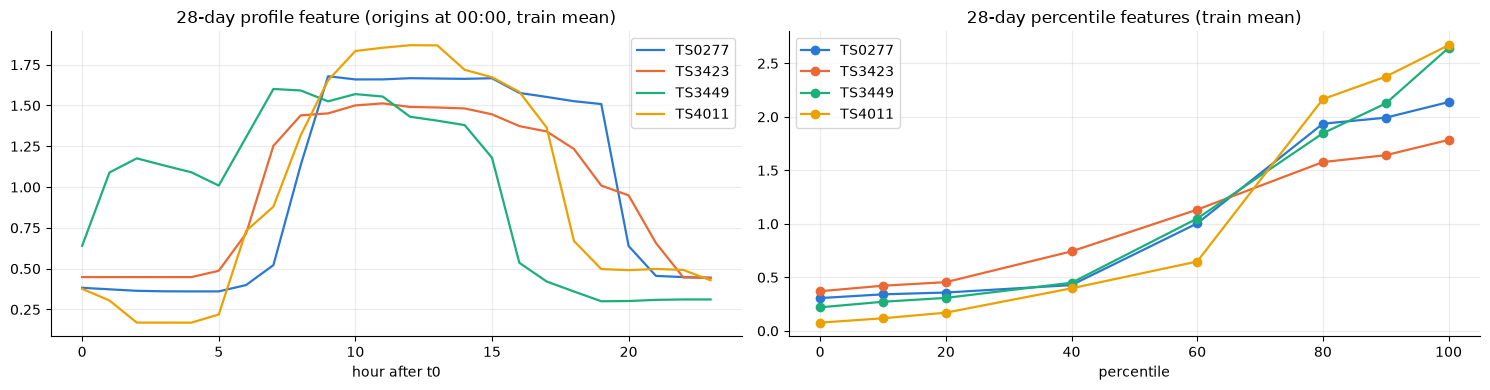

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for n in T.SERIES:
    s = data[n].static["train"]; nm = T.static_names(data[n])
    i0 = nm.index("profile_h0"); ip = [nm.index(f"p{p}_28d") for p in (0, 10, 20, 40, 60, 80, 90, 100)]
    hrs = data[n].hourly.index[data[n].t0["train"]].hour
    sel = hrs == 0
    axes[0].plot(range(24), s[sel, i0:i0 + 24].mean(0), color=SCOL[n], label=n)
    axes[1].plot([0, 10, 20, 40, 60, 80, 90, 100], s[:, ip].mean(0), "o-", color=SCOL[n], label=n)
axes[0].set(title="28-day profile feature (origins at 00:00, train mean)", xlabel="hour after t0")
axes[1].set(title="28-day percentile features (train mean)", xlabel="percentile")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

## **7. Generic model with dynamic and static features**

One model is trained on the pooled training origins of **all four series** (each in its own normalized units) and evaluated on each held-out test year. Dynamic input = consumption + 7 calendar channels (section 5). The static vector $s$ (48 features) enters the network in one of the ways studied by Miebs et al. (2020) and in the lecture, plus two reference points and one extension:

| variant | how static features are used |
|---|---|
| `none` | no static features – pooled dynamic-only model |
| `seq` | naive: $s$ is repeated and appended to the input at every time step |
| `concat` | Miebs #1: $z = \text{FNN}(s)$ (2 × Dense(32)); $[h_T, z]$ → head |
| `init` | Miebs #2: $h_0 = \tanh(W_h z)$, $c_0 = W_c z$ initialize the LSTM |
| `hybrid` | Miebs #3: init + concat |
| `film` | **extension**: init + FiLM – $z$ produces per-channel scale/shift $(\gamma,\beta)$ applied to the dynamic input at every step ($x_t(1+\gamma_x)+\beta_x$) and to the final hidden state ($h_T(1+\gamma_h)+\beta_h$); initialized as identity |

The FiLM variant extends the idea of Miebs et al. from *where* the static information is injected to *how*: instead of only adding information
(concatenation) or a starting point (initialization), the customer context multiplicatively re-weights the dynamic channels, e.g. it can switch off
the weekend channel for a continuously operating customer. Same LSTM(64) and head as before, same training procedure (training origins every 4 h of every series, ≈ 24 k windows per epoch).

In [18]:
MODES = ["none", "seq", "concat", "init", "hybrid", "film"]
generic = {m: T.run_experiment(f"generic_{m}", list(data.values()), use_cal=True, static_mode=m, stride=4) for m in MODES}

rows = []
for m, (met, hist, _) in generic.items():
    for n in T.SERIES:
        rows.append({"model": f"generic/{m}", "series": n, "mean RMSE": met[n].RMSE.mean(), "mean MAE": met[n].MAE.mean(),
                     "RMSE h=1": met[n].RMSE.iloc[0], "RMSE h=24": met[n].RMSE.iloc[-1]})
for lab, res in [("per-series y", per_y), ("per-series y+cal", per_cal)]:
    for n in T.SERIES:
        r = res[n][0]
        rows.append({"model": lab, "series": n, "mean RMSE": r.RMSE.mean(), "mean MAE": r.MAE.mean(),
                     "RMSE h=1": r.RMSE.iloc[0], "RMSE h=24": r.RMSE.iloc[-1]})
for n in T.SERIES:
    r = naive168[n]
    rows.append({"model": "naive t-168h", "series": n, "mean RMSE": r.RMSE.mean(), "mean MAE": r.MAE.mean(),
                 "RMSE h=1": r.RMSE.iloc[0], "RMSE h=24": r.RMSE.iloc[-1]})
allres = pd.DataFrame(rows)
order = ["naive t-168h", "per-series y", "per-series y+cal"] + [f"generic/{m}" for m in MODES]
tab = allres.pivot(index="model", columns="series", values="mean RMSE").loc[order]
tab["average"] = tab.mean(1)
print("Mean test RMSE over horizons 1..24 (normalized units, lower is better)")
display(tab.round(4).style.highlight_min(axis=0, color="red"))
tab_mae = allres.pivot(index="model", columns="series", values="mean MAE").loc[order]
tab_mae["average"] = tab_mae.mean(1)
print("Mean test MAE over horizons 1..24")
display(tab_mae.round(4).style.highlight_min(axis=0, color="red"))

Mean test RMSE over horizons 1..24 (normalized units, lower is better)


series,TS0277,TS3423,TS3449,TS4011,average
model,,,,,
naive t-168h,0.251500,0.133400,0.325900,0.532600,0.310900
per-series y,0.237500,0.122000,0.271900,0.459500,0.272700
per-series y+cal,0.199900,0.105000,0.262400,0.455700,0.255700
generic/none,0.199200,0.110000,0.267600,0.469300,0.261500
generic/seq,0.199900,0.108500,0.286700,0.443800,0.259700
generic/concat,0.203900,0.115600,0.267000,0.475300,0.265400
generic/init,0.201300,0.112200,0.256200,0.469600,0.259900
generic/hybrid,0.200900,0.112300,0.265800,0.478000,0.264300
generic/film,0.198600,0.112600,0.270600,0.461800,0.260900


Mean test MAE over horizons 1..24


series,TS0277,TS3423,TS3449,TS4011,average
model,,,,,
naive t-168h,0.089100,0.070100,0.159200,0.260100,0.144600
per-series y,0.119500,0.074600,0.164600,0.272700,0.157800
per-series y+cal,0.108300,0.065100,0.179700,0.284600,0.159400
generic/none,0.108100,0.071300,0.168400,0.290700,0.159600
generic/seq,0.110200,0.069900,0.188300,0.279400,0.161900
generic/concat,0.114000,0.077700,0.173300,0.294100,0.164800
generic/init,0.111500,0.075400,0.165800,0.293700,0.161600
generic/hybrid,0.109800,0.073700,0.174000,0.293000,0.162600
generic/film,0.111600,0.076900,0.180800,0.288900,0.164600


The differences between the variants are small, so each generic variant was trained with **three random seeds** (0, 1, 2 – different weight
initialization and batch order, same data). The table shows mean ± standard deviation of the mean RMSE across seeds; a difference smaller than
about two standard deviations should not be interpreted.

In [19]:
seed_rows = []
for m in MODES:
    for seed in (0, 1, 2):
        tag = f"generic_{m}" + ("" if seed == 0 else f"_s{seed}")
        met = generic[m][0] if seed == 0 else T.run_experiment(tag, list(data.values()), use_cal=True, static_mode=m,
                                                                stride=4, seed=seed)[0]
        r = {n: met[n].RMSE.mean() for n in T.SERIES}
        seed_rows.append({"variant": m, "seed": seed, **r, "average": np.mean(list(r.values()))})
seeds_df = pd.DataFrame(seed_rows)
agg = seeds_df.groupby("variant")[T.SERIES + ["average"]].agg(["mean", "std"]).loc[MODES]
fmt = pd.DataFrame({c: [f"{agg.loc[m, (c, 'mean')]:.4f} ± {agg.loc[m, (c, 'std')]:.4f}" for m in MODES]
                    for c in T.SERIES + ["average"]}, index=MODES)
display(fmt)
gain = (1 - agg[("average", "mean")] / agg.loc["none", ("average", "mean")]) * 100
print("average RMSE reduction vs. generic/none [%]:", gain.round(2).to_dict())

,TS0277,TS3423,TS3449,TS4011,average
none,0.2038 ± 0.0056,0.1130 ± 0.0035,0.2671 ± 0.0196,0.4721 ± 0.0025,0.2640 ± 0.0040
seq,0.2001 ± 0.0037,0.1088 ± 0.0059,0.2784 ± 0.0072,0.4507 ± 0.0075,0.2595 ± 0.0035
concat,0.2056 ± 0.0054,0.1136 ± 0.0021,0.2695 ± 0.0022,0.4720 ± 0.0030,0.2652 ± 0.0018
init,0.2028 ± 0.0043,0.1152 ± 0.0047,0.2573 ± 0.0019,0.4746 ± 0.0043,0.2625 ± 0.0028
hybrid,0.1999 ± 0.0009,0.1084 ± 0.0045,0.2682 ± 0.0036,0.4695 ± 0.0115,0.2615 ± 0.0032
film,0.2003 ± 0.0027,0.1128 ± 0.0017,0.2633 ± 0.0067,0.4681 ± 0.0057,0.2611 ± 0.0003


average RMSE reduction vs. generic/none [%]: {'none': 0.0, 'seq': 1.71, 'concat': -0.43, 'init': 0.58, 'hybrid': 0.95, 'film': 1.09}


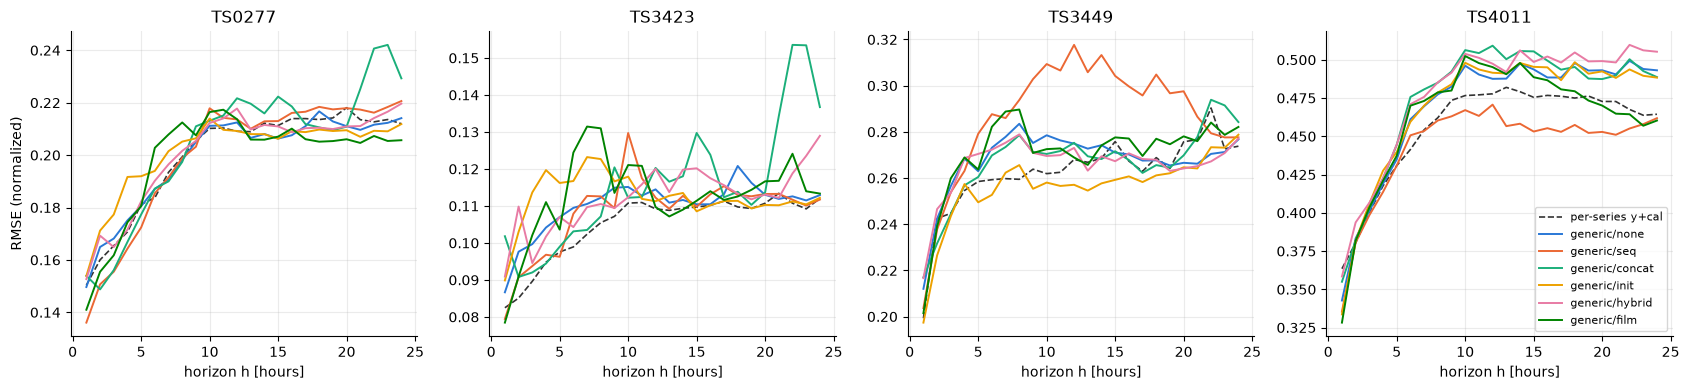

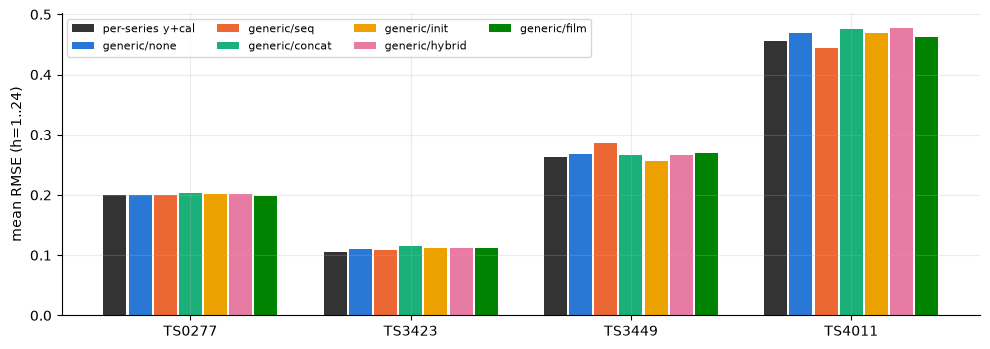

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True)
MCOL = dict(zip(MODES, PALETTE[:6]))
for a, n in zip(axes, T.SERIES):
    a.plot(per_cal[n][0].horizon, per_cal[n][0].RMSE, color="#333333", ls="--", lw=1.2, label="per-series y+cal")
    for m in MODES:
        a.plot(generic[m][0][n].horizon, generic[m][0][n].RMSE, color=MCOL[m], lw=1.4, label=f"generic/{m}")
    a.set_title(n); a.set_xlabel("horizon h [hours]")
axes[0].set_ylabel("RMSE (normalized)"); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(T.SERIES)); w = 0.8 / (len(MODES) + 1)
ax.bar(x - 0.4 + w / 2, tab.loc["per-series y+cal", T.SERIES], w - 0.01, color="#333333", label="per-series y+cal")
for i, m in enumerate(MODES):
    ax.bar(x - 0.4 + w * (i + 1.5), tab.loc[f"generic/{m}", T.SERIES], w - 0.01, color=MCOL[m], label=f"generic/{m}")
ax.set_xticks(x, T.SERIES); ax.set_ylabel("mean RMSE (h=1..24)"); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

best generic variant by average RMSE: seq


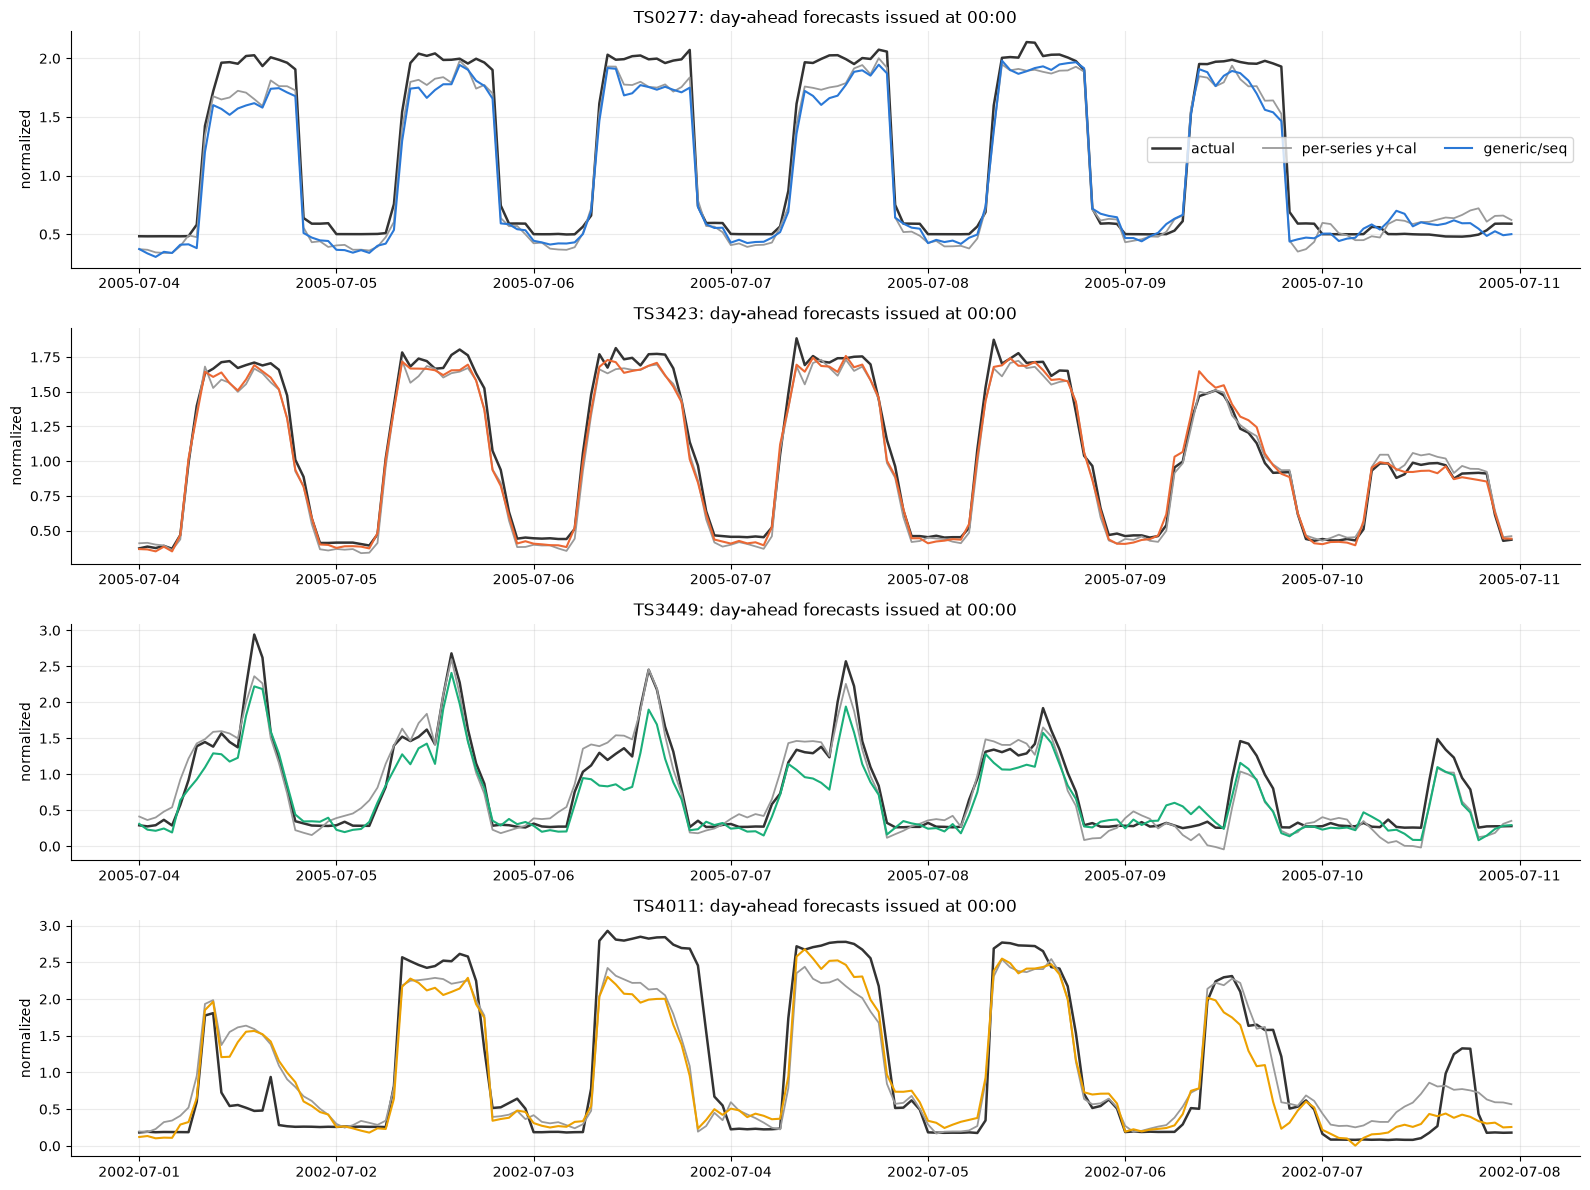

In [21]:
# day-ahead forecasts issued at midnight for one test week (Mon..Sun), best generic variant vs per-series model
best = tab.loc[[f"generic/{m}" for m in MODES], "average"].idxmin().split("/")[1]
print("best generic variant by average RMSE:", best)
fig, axes = plt.subplots(4, 1, figsize=(16, 12))
for a, n in zip(axes, T.SERIES):
    d = data[n]; idx = d.hourly.index
    P_g, P_p = generic[best][2][n], per_cal[n][2]
    t0 = P_g[:, 0].astype(int)
    k = np.where((idx[t0].dayofweek == 0) & (idx[t0] >= idx[t0[0]] + pd.Timedelta(days=150)))[0][0]
    days = range(k, k + 7)
    tt = np.concatenate([np.arange(t0[i], t0[i] + 24) for i in days])
    a.plot(idx[tt], d.y[tt], color="#333333", lw=1.8, label="actual")
    a.plot(idx[tt], np.concatenate([P_p[i, 1:] for i in days]), color="#9a9a9a", lw=1.3, label="per-series y+cal")
    a.plot(idx[tt], np.concatenate([P_g[i, 1:] for i in days]), color=SCOL[n], lw=1.5, label=f"generic/{best}")
    a.set_title(f"{n}: day-ahead forecasts issued at 00:00"); a.set_ylabel("normalized")
axes[0].legend(ncol=3); plt.tight_layout(); plt.show()

### **Findings**: generic model with static features

**1. One generic model is about as good as four specialists.** The pooled dynamic-only model (`generic/none`, average RMSE ≈ 0.264 over 3 seeds)
is within ≈ 3 % of the per-series calendar models (≈ 0.256) and beats the weekly-naive baseline (0.311) by ≈ 15 %. Without static features
it is slightly worse than the specialist for every customer (by 1–8 %, most for `TS3423`), i.e. one shared network costs a little accuracy;
with static features (`seq`) the generic model is better than the specialist for `TS4011` (0.451 vs. 0.456) – the customer with only one training
year profits from the other customers' data once it is told which profile it is forecasting. After normalization by the training mean the four
customers are similar enough to share one network.

**2. The static-feature strategies differ by less than the seed-to-seed noise.** Averaged over three seeds the ranking is
`seq` (−1.7 % RMSE vs. `none`) < `film` (−1.1 %) ≈ `hybrid` (−1.0 %) < `init` (−0.6 %) < `none` < `concat` (+0.4 %), while the standard deviation
across seeds is ≈ 0.002–0.004 (≈ 1–1.5 %). None of the average differences is clearly significant. Per customer there are two effects that are
larger than the noise:
* `TS4011`: static inputs via `seq` reduce RMSE from 0.472 ± 0.003 to 0.451 ± 0.008 (−4.5 %) – the customer with the least data and the most irregular
  (holiday-heavy) behaviour profits from the explicit 28-day level, percentiles and weekend ratio;
* `TS3449`: state initialization (`init`) reduces RMSE from 0.267 ± 0.020 to 0.257 ± 0.002 and, notably, makes training much more stable across seeds –
  the static context gives the LSTM a sensible starting state for this unusual (night-heating) profile.

**3. Why the gains are smaller than in Miebs et al.** In the paper (and in the lecture's idealized example) the static features carry information the
sequence cannot provide – customer type / amplitude that distinguishes otherwise similar sequences. Here the dynamic input already contains most
of it: (i) each series is normalized by its own mean, (ii) the one-week input window already shows the daily profile, the weekend ratio and the
current level (much of what the 28-day aggregates summarize), (iii) calendar inputs already tell the model the hour and weekday, and (iv) the linear
highway already provides the weekly-naive forecast. With only four customers the network can also recognize each of them from the dynamic input alone.
Static conditioning should matter more with many heterogeneous customers, short input windows, or unnormalized data.

**4. Architectural observations (tendencies – on average not significant, see point 2).** Initializing the state (`init`, `hybrid`, `film`)
injects the static context without widening the input, and the context influences all 168 recurrent steps; for `TS3449` it also made training
clearly more stable across seeds (`init`: std 0.002 vs. 0.020 for `none`), although this does not hold for every customer. Late concatenation
alone (`concat`) gave no gain at all – appending 32 latent values right before the head adds parameters but no new temporal information. The naive
`seq` strategy works surprisingly well here, probably because the static vector is small relative to the dynamic data and the LSTM gates can learn
to use or ignore it. The FiLM extension (multiplicative modulation of the inputs and the final state, plus initialization) is on par with the best
Miebs variant and has the lowest seed-to-seed variance of the average RMSE (± 0.0003), so it is a reasonable generalization of the init/hybrid
ideas, but it does not give a substantial gain on this data set.

## **8. Summary**

| question | answer |
|---|---|
| Components | Daily (55–85 % of hourly variance) and weekly (11–33 %) seasonality dominate; no monthly cycle; yearly winter peak for `TS3449`/`TS4011`/`TS0277`; clear upward trend only for `TS3423` (+14 %); residuals 2–8 %, mostly holidays. |
| Forecast quality vs. horizon | RMSE rises steeply for the first 5–7 h and is flat afterwards; $h_{24}/h_1 \approx$ 1.2–1.5. Customer predictability matters more than the horizon (RMSE ≈ 0.10 of the mean load for `TS3423` to ≈ 0.46 for `TS4011`). LSTM skill vs. weekly-naive: 6–17 % (y only), 14–21 % with calendar inputs. |
| Calendar features | −14 to −16 % RMSE for the regular customers `TS0277`, `TS3423`; ≈ 0 for `TS3449`, `TS4011` (short history / irregular). |
| Static features | 48 features (calendar of $t_0$, 28-day aggregates, percentiles, trend, 28-day daily profile, weekend ratio), computed from past data only (verified). |
| Generic model | One pooled model ≈ per-series models (within ≈ 3 %). Static-feature strategies differ by ≤ 1.7 % on average – within seed noise; clear gains only for `TS4011` (`seq`, −4.5 %) and in training stability for `TS3449` (`init`). FiLM extension ≈ best Miebs variant with the lowest variance. |

**Limitations.** CPU-only training with a small budget (1-layer LSTM(64), ≤ 15 epochs, training windows sub-sampled every 3–4 h); hourly instead of
15-min resolution; holidays are not encoded (they produce the largest errors); three seeds only for the generic models and one for the per-series models.